# 05. Modelo de demanda

Fase 5. Elasticidade-preço do público de mercado, com incerteza. Sem
receita ótima.

**Unidade de análise:** setor x jogo.

- `preco`: preço do subconjunto identificador (regime mercado,
  `preco_regulado` falso) no setor e jogo. Setor-jogo com mais de um preço
  distinto é descartado e contado.
- `q`: soma de todos os ingressos de regime mercado vendidos no setor e
  jogo, não só a Inteira. Quem escolhe o setor pelo preço da Inteira pode
  comprar a Meia; modelar só a Inteira confundiria composição com
  quantidade.
- `id_setor`: mandante + " | " + setor. O mesmo nome de setor em clubes
  diferentes é setor diferente.

**Especificações, declaradas antes de qualquer resultado.** Em todas,
log(q) = beta * log(preco) + efeitos fixos, erro padrão agrupado por jogo.

- E1: efeito fixo de partida.
- E2: efeito fixo de partida e de setor. **Principal.**
- E3: E2 estimada separadamente em cada temporada.

As três vão para o relatório, qualquer que seja o resultado.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from linearmodels import PanelOLS

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = RAIZ / "figuras" / "05_modelo"
FIG.mkdir(parents=True, exist_ok=True)

base = pd.read_csv(RAIZ / "data" / "03_processed" / "boletins.csv")
merc = base[base.regime == "mercado"]
chave = ["ano", "jogo", "mandante", "setor"]

ident = merc[~merc.preco_regulado]
precos = ident.groupby(chave).preco.agg(["nunique", "first"])
q = merc.groupby(chave).vendidos.sum().rename("q")
multiplos = (precos["nunique"] > 1).sum()
sem_preco = len(q.index.difference(precos.index))

d = (precos[precos["nunique"] == 1]["first"].rename("preco").to_frame()
     .join(q, how="inner").reset_index())
d["id_setor"] = d.mandante + " | " + d.setor
d["id_jogo"] = d.ano.astype(str) + "_" + d.jogo.astype(str)
d["lq"] = np.log(d.q)
d["lp"] = np.log(d.preco)
assert (d.q > 0).all() and (d.preco > 0).all()

print(f"Setor-jogo de regime mercado: {len(q):,}")
print(f"  sem preço do subconjunto identificador (fora): {sem_preco:,}")
print(f"  com mais de um preço distinto (descartados): {multiplos:,}")
print(f"Unidades na estimação: {len(d):,}  jogos: {d.id_jogo.nunique()}  setores: {d.id_setor.nunique()}")

Setor-jogo de regime mercado: 2,562
  sem preço do subconjunto identificador (fora): 341
  com mais de um preço distinto (descartados): 9
Unidades na estimação: 2,212  jogos: 387  setores: 337


## Estimação

`PanelOLS` com o setor como entidade e o jogo como tempo. E1 usa só o
efeito de tempo (partida); E2 usa os dois. Erro padrão agrupado por jogo
(`cluster_time=True`).

In [2]:
def painel(df):
    df = df.copy()
    df["t"] = pd.factorize(df.id_jogo)[0]
    return df.set_index(["id_setor", "t"])


def estimar(df, setor, nome):
    p = painel(df)
    r = PanelOLS(p.lq, p[["lp"]], entity_effects=setor, time_effects=True).fit(
        cov_type="clustered", cluster_time=True)
    ic = r.conf_int().loc["lp"]
    return r, {"especificacao": nome, "beta": r.params.lp, "erro_padrao": r.std_errors.lp,
               "ic95_inf": ic.lower, "ic95_sup": ic.upper, "n_obs": int(r.nobs),
               "n_jogos": df.id_jogo.nunique(), "n_setores": df.id_setor.nunique()}


linhas = []
r1, l = estimar(d, False, "E1: EF partida")
linhas.append(l)
r2, l = estimar(d, True, "E2: EF partida + setor (principal)")
linhas.append(l)
for ano in sorted(d.ano.unique()):
    _, l = estimar(d[d.ano == ano], True, f"E3: E2 em {ano}")
    linhas.append(l)

## Conferência do beta de E2

Implementação própria: centralização alternada dentro de setor e dentro de
jogo até convergir, depois OLS simples sem intercepto. O beta tem que bater
com o do `PanelOLS`.

In [3]:
def centralizar(df, colunas, grupos, tol=1e-12, max_iter=10000):
    x = df[colunas].copy()
    for i in range(max_iter):
        anterior = x.copy()
        for g in grupos:
            x = x - x.groupby(df[g]).transform("mean")
        if (x - anterior).abs().max().max() < tol:
            return x, i + 1
    raise RuntimeError("não convergiu")


cent, iteracoes = centralizar(d, ["lq", "lp"], ["id_setor", "id_jogo"])
beta_proprio = (cent.lp * cent.lq).sum() / (cent.lp ** 2).sum()
print(f"Beta próprio: {beta_proprio:.10f} ({iteracoes} iterações)")
print(f"Beta PanelOLS: {r2.params.lp:.10f}")
print(f"Diferença absoluta: {abs(beta_proprio - r2.params.lp):.2e}")
assert abs(beta_proprio - r2.params.lp) < 1e-8

dp_residual = cent.lp.std(ddof=0)
print(f"Desvio-padrão de log(preco): bruto {d.lp.std(ddof=0):.4f}; "
      f"após EF de partida {(d.lp - d.groupby('id_jogo').lp.transform('mean')).std(ddof=0):.4f}; "
      f"após EF de partida e setor (E2) {dp_residual:.4f}")
singletons = d.id_setor.map(d.id_setor.value_counts()) == 1
print(f"Setores com uma só observação: {d[singletons].id_setor.nunique()} "
      f"(log preço centralizado = 0 por construção). Sem eles: {cent.lp[~singletons].std(ddof=0):.4f}")

Beta próprio: -0.4680217227 (417 iterações)
Beta PanelOLS: -0.4680217227
Diferença absoluta: 3.33e-16
Desvio-padrão de log(preco): bruto 0.6633; após EF de partida 0.3593; após EF de partida e setor (E2) 0.1010
Setores com uma só observação: 113 (log preço centralizado = 0 por construção). Sem eles: 0.1037


## Censura

Não há capacidade de setor na base, então não dá para saber quem esgotou.
Proxy: para cada `id_setor`, o máximo histórico de `q` na base;
`ocupacao_aparente = q / máximo`. E2 é reestimada sem as unidades com
`ocupacao_aparente >= 0,90`.

**Isto é proxy, não medida.** O máximo histórico subestima a capacidade,
então o filtro é conservador e não resolve a censura. Por construção, a
observação de máximo de cada setor tem ocupação 1 e sai do filtro; setores
com uma só observação saem inteiros.

In [4]:
d["q_max_setor"] = d.groupby("id_setor").q.transform("max")
d["ocupacao_aparente"] = d.q / d.q_max_setor
fora = d.ocupacao_aparente >= 0.90
print(f"Unidades com ocupação aparente >= 0,90: {fora.sum():,} de {len(d):,}")
_, l = estimar(d[~fora], True, "E2 sem ocupação aparente >= 0,90")
linhas.append(l)

tabela = pd.DataFrame(linhas)
pd.set_option("display.width", 200)
print(tabela.round(4).to_string(index=False))
tabela.round(6).to_csv(FIG / "tabela_estimativas.csv", index=False)

Unidades com ocupação aparente >= 0,90: 447 de 2,212
                     especificacao    beta  erro_padrao  ic95_inf  ic95_sup  n_obs  n_jogos  n_setores
                    E1: EF partida -0.7691       0.1133   -0.9914   -0.5468   2212      387        337
E2: EF partida + setor (principal) -0.4680       0.2116   -0.8831   -0.0529   2212      387        337
                    E3: E2 em 2023 -1.1912       0.4336   -2.0440   -0.3384    630      109        179
                    E3: E2 em 2024 -1.1699       0.7320   -2.6099    0.2701    602      104        169
                    E3: E2 em 2025 -0.3208       0.3399   -0.9893    0.3477    593      103        131
                    E3: E2 em 2026  0.2665       0.4978   -0.7156    1.2486    387       71        129
  E2 sem ocupação aparente >= 0,90 -0.8114       0.2548   -1.3113   -0.3115   1765      364        215


## Resíduo contra valor ajustado (E2)

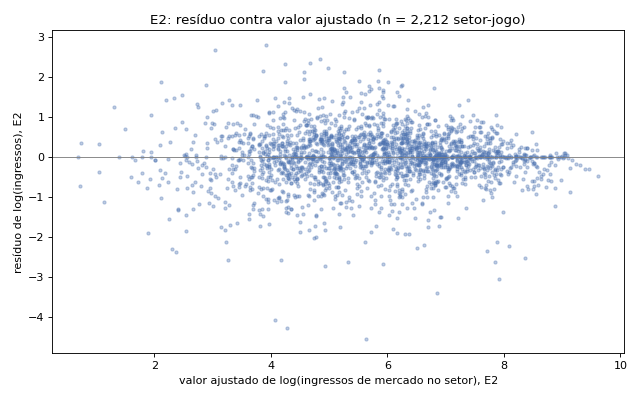

Desvio-padrão do resíduo: 0.6842


In [5]:
residuo = r2.idiosyncratic.idiosyncratic
ajustado = painel(d).lq - residuo
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(ajustado, residuo, s=8, alpha=0.35, color="#4C72B0")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("valor ajustado de log(ingressos de mercado no setor), E2")
ax.set_ylabel("resíduo de log(ingressos), E2")
ax.set_title(f"E2: resíduo contra valor ajustado (n = {len(d):,} setor-jogo)")
fig.tight_layout()
fig.savefig(FIG / "residuo_ajustado_E2.png", dpi=150)
plt.show()
print(f"Desvio-padrão do resíduo: {residuo.std(ddof=0):.4f}")